# Data pipeline

This notebook rebuilds every file in `Data/processed/` from the raw sources in `Data/raw/`, then shows the tables the models will use.

1. Extract CBAM default values and benchmarks (`scripts/extract_cbam_tables.py`).
2. Match Lei et al. (2023) plant emissions to Global Energy Monitor plants (`scripts/match_lei_gem.py`).
3. Tidy the Comext EU import data (`scripts/process_comext.py`) and the GEM furnace charge mix (`scripts/gem_charge_mix.py`).
4. Look at the results: policy parameters, defaults and benchmarks for key goods, and how plant-level intensities compare with the default values.

The calibrated trees built from these tables are in `notebooks/02_calibrated_trees.ipynb`.

Run all cells from top to bottom. It takes under a minute.

In [1]:
import subprocess, sys
from pathlib import Path
import pandas as pd

# repo root, from notebooks/ or the top folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, PARAMS = ROOT / "Data/raw", ROOT / "Data/processed", ROOT / "Data/parameters"
pd.set_option("display.max_columns", 30, "display.width", 200)
print("Repository folder found:", ROOT.name)

Repository folder found: build


## 1. Default values and benchmarks

In [2]:
# relative paths, so reports don't record local paths
cmd = [sys.executable, "scripts/extract_cbam_tables.py",
       "--defaults", "Data/raw/cbam_tables/DV correcting act_final update_06.08.xlsx",
       "--benchmarks", "Data/raw/cbam_tables/CBAM Benchmarks_20260206.xlsx",
       "--out", "Data/processed"]
print(subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True, check=True).stdout[-1500:])

gins: ['China', 'India', 'Türkiye', 'Viet Nam'] + ['UNKNOWN ORIGIN (Annex IV)', 'OTHER COUNTRIES AND TERRITORIES']
defaults_long rows: 1470 (aggregate 'see below' rows: 126)
benchmarks_long rows: 2389 (536 CN8 codes)
defaults_with_benchmarks rows: 3216
  Column B match 2026-27: exact=2502, plain=714
  Column B match 2028-30: exact=2502, plain=714
  Column A match 2026-27: exact=216, plain=3000
  ('ambiguous' = the default allows two routes, e.g. carbon or low-alloy steel;
   the candidates column lists every value)

rows per origin and sector (defaults, excluding aggregate rows):
  China                               aluminium       24
  China                               iron and steel  200
  India                               aluminium       24
  India                               iron and steel  200
  OTHER COUNTRIES AND TERRITORIES     aluminium       24
  OTHER COUNTRIES AND TERRITORIES     iron and steel  200
  Türkiye                             aluminium       24
  Türkiye  

## 2. Plant emissions matched to GEM plants

In [3]:
cmd = [sys.executable, "scripts/match_lei_gem.py",
       "--lei", "Data/raw/lei2023/PlantEmission_v2.xlsx",
       "--gem", "Data/raw/gem/Plant-level data - Global Iron and Steel Tracker - September 2026 (V1).xlsx",
       "--out", "Data/processed/lei_gem"]
print(subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True, check=True).stdout)

CHN: Lei sites 769 (1661.8 Mt CO2). Matched 180 sites = 56.4% of emissions, in 91 groups (48 one-to-one). Groups with 2019 production: 7.
    groups usable for spread: yes=73, no: implausible ratio (mismatch or scope gap)=10, no: large group (>5 sites or plants)=5, no: no GEM steel capacity=3
    tiers: no candidate=510, company+location=171, ambiguous company, no location=48, ambiguous (>4 plants)=31, company only (unique)=9
IND: Lei sites 351 (221.7 Mt CO2). Matched 40 sites = 46.1% of emissions, in 25 groups (12 one-to-one). Groups with 2019 production: 4.
    groups usable for spread: yes=14, no: no GEM steel capacity=8, no: implausible ratio (mismatch or scope gap)=3
    tiers: no candidate=268, ambiguous company, no location=43, company+location=34, company only (unique)=6
TUR: Lei sites 118 (24.4 Mt CO2). Matched 35 sites = 71.4% of emissions, in 16 groups (7 one-to-one). Groups with 2019 production: 2.
    groups usable for spread: yes=13, no: large group (>5 sites or plants)=1

## 2b. EU imports (Eurostat Comext) and furnace charge mix (GEM)

Comext gives EU imports by CN code and origin in tonnes and euros; the trees use it to anchor export volumes. The GEM steel-unit file gives the scrap, DRI and pig-iron shares of arc and induction furnaces; the trees use it for precursor masses.

In [4]:
cmd = [sys.executable, "scripts/process_comext.py", "--inputs", "Data/raw/comtext/*.csv", "--out", "Data/processed"]
print(subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True, check=True).stdout)
cmd = [sys.executable, "scripts/gem_charge_mix.py",
       "--gem-units", "Data/raw/gem/Steel unit data - Global Iron and Steel Tracker - September 2026 (V1).xlsx",
       "--out", "Data/processed"]
print(subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True, check=True).stdout)

files: 2; years: ['2024', '2025']; CN8 rows kept: 5351
  2024: CN aluminium 744 kt, CN iron and steel 8,053 kt, IN aluminium 306 kt, IN iron and steel 4,970 kt, TR aluminium 693 kt, TR iron and steel 6,979 kt, VN aluminium 26 kt, VN iron and steel 3,491 kt
  2025: CN aluminium 758 kt, CN iron and steel 10,691 kt, IN aluminium 316 kt, IN iron and steel 4,472 kt, TR aluminium 725 kt, TR iron and steel 8,046 kt, VN aluminium 23 kt, VN iron and steel 3,024 kt



China    EAF units  21/306 scrap  77.6%  DRI   0.0%  merchant pig iron  21.6%
India    EAF units  25/35  scrap  15.9%  DRI  49.8%  merchant pig iron   1.7%
Türkiye  EAF units  23/31  scrap  91.8%  DRI   0.0%  merchant pig iron   0.0%
Vietnam  EAF units   4/13  scrap  99.7%  DRI   0.0%  merchant pig iron   0.3%
India    IF  units 144/271 scrap   8.9%  DRI  77.3%  merchant pig iron   2.6%
Vietnam  IF  units   1/4   scrap 100.0%  DRI   0.0%  merchant pig iron   0.0%



In [5]:
imp = pd.read_csv(PROC / "comext_by_category.csv")
(imp[imp.year == 2025].pivot_table(index=["sector", "goods_category"], columns="origin_iso2", values="tonnes", aggfunc="sum")
    .div(1000).round(0).rename_axis(columns="origin (kt, 2025)"))

origin (kt, 2025)                          CN      IN      TR      VN
sector         goods_category                                        
aluminium      aluminium products       746.0    69.0   673.0    16.0
               unwrought aluminium       12.0   247.0    52.0     7.0
iron and steel DRI                        0.0     0.0     0.0     NaN
               FeCr                       2.0    23.0    51.0     NaN
               FeMn                       0.0   151.0     1.0     0.0
               FeNi                       0.0     0.0     0.0     NaN
               crude steel             1608.0   551.0   245.0   740.0
               iron or steel products  9077.0  3626.0  7749.0  2283.0
               pig iron                   0.0   120.0     0.0     NaN
               sintered ore               4.0     0.0     0.0     0.0

## 3. Policy parameters

CBAM factor, default mark-ups, 2026 certificate prices and the cross-sectoral correction factor. Each row names its source.

In [6]:
pol = pd.read_csv(PARAMS / "policy_parameters.csv")
pol[["parameter", "period", "value", "unit", "status", "source"]]

,parameter,period,value,unit,status,source
0,cbam_factor,2026,0.975,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
1,cbam_factor,2027,0.950,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
2,cbam_factor,2028,0.900,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
3,cbam_factor,2029,0.775,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
4,cbam_factor,2030,0.515,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
5,cbam_factor,2031,0.390,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
6,cbam_factor,2032,0.265,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
7,cbam_factor,2033,0.140,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
8,cbam_factor,2034,0.000,share of benchmark deducted,legislated,Directive 2003/87/EC Art. 10a(1a); OPIS/McClos...
9,default_markup,2026,0.100,share added to base default value,legislated,IR (EU) 2025/2621; OPIS/McCloskey table


## 4. Defaults and benchmarks for key steel goods

Base default values (before the mark-up) for four origins, with the Column B benchmark (used with defaults) and the Column A benchmark (used with verified actual values) for 2026–27. Column A is process-level: it excludes the precursors, which carry their own benchmarks.

In [7]:
dwb = pd.read_csv(PROC / "defaults_with_benchmarks.csv", dtype={"cn8": str})
key_goods = {"72011011": "Pig iron", "72071111": "Slab / billet", "72083900": "Hot-rolled coil", "72091790": "Cold-rolled coil"}
origins = ["China", "India", "Türkiye", "Viet Nam", "OTHER COUNTRIES AND TERRITORIES"]
sel = dwb[dwb.cn8.isin(key_goods) & dwb.origin.isin(origins)].copy()
sel["good"] = sel.cn8.map(key_goods)
table = sel.pivot_table(index="good", columns="origin", values="default_total_tco2e_per_t", aggfunc="first")
bm = sel.groupby("good")[["bm_colB_2026_27", "bm_colA_2026_27"]].first()
table.join(bm).loc[list(key_goods.values())].round(3)

,China,India,OTHER COUNTRIES AND TERRITORIES,Türkiye,Viet Nam,bm_colB_2026_27,bm_colA_2026_27
good,,,,,,,
Pig iron,1.660,2.53,3.480,1.850,2.19,1.210,1.089
Slab / billet,3.169,4.27,3.996,2.310,2.35,1.364,0.188
Hot-rolled coil,3.187,4.28,4.049,2.428,2.35,1.370,0.044
Cold-rolled coil,3.205,4.28,4.101,2.510,2.37,1.458,0.079


## 5. How much plants differ within a country

Each row summarises the matched plant groups for one country and route. `robust_cv` is (P90 − P10) / (2 × 1.2816 × median), a spread measure that is not thrown off by a few odd matches. Intensity is 2019 emissions divided by 2019 crude-steel production where GEM reports it (`intensity_per_t_prod`), otherwise by operating capacity (`intensity_per_t_cap`, which reads low for plants running below capacity).

In [8]:
spread = pd.read_csv(PROC / "lei_gem/intensity_spread_summary.csv")
spread[spread.route_class.isin(["BF-BOF", "scrap-EAF/IF", "DRI-EAF/IF"])]

,basis,iso3,route_class,n_groups,emissions_mt,w_median,w_p10,w_p90,unweighted_median,robust_cv
0,intensity_per_t_prod,CHN,BF-BOF,7,52.96,1.880,1.293,2.457,1.880,0.242
2,intensity_per_t_prod,IND,BF-BOF,3,31.86,1.443,1.428,1.945,1.443,0.140
5,intensity_per_t_prod,TUR,BF-BOF,2,14.31,1.609,1.609,1.665,1.637,NaN
7,intensity_per_t_prod,VNM,BF-BOF,1,14.05,2.161,2.161,2.161,2.161,NaN
9,intensity_per_t_cap,CHN,BF-BOF,58,459.68,1.559,0.785,2.351,1.302,0.392
12,intensity_per_t_cap,CHN,scrap-EAF/IF,7,1.55,0.240,0.084,1.190,0.109,1.798
13,intensity_per_t_cap,IND,BF-BOF,7,51.58,1.441,1.091,1.951,1.259,0.233
14,intensity_per_t_cap,IND,DRI-EAF/IF,4,4.09,1.779,1.286,2.881,1.532,0.350
17,intensity_per_t_cap,TUR,BF-BOF,2,14.31,1.561,1.384,1.561,1.472,NaN
19,intensity_per_t_cap,TUR,scrap-EAF/IF,11,2.80,0.108,0.073,0.249,0.108,0.636


In [9]:
print((PROC / "lei_gem/match_report.txt").read_text())

CHN: Lei sites 769 (1661.8 Mt CO2). Matched 180 sites = 56.4% of emissions, in 91 groups (48 one-to-one). Groups with 2019 production: 7.
    groups usable for spread: yes=73, no: implausible ratio (mismatch or scope gap)=10, no: large group (>5 sites or plants)=5, no: no GEM steel capacity=3
    tiers: no candidate=510, company+location=171, ambiguous company, no location=48, ambiguous (>4 plants)=31, company only (unique)=9
IND: Lei sites 351 (221.7 Mt CO2). Matched 40 sites = 46.1% of emissions, in 25 groups (12 one-to-one). Groups with 2019 production: 4.
    groups usable for spread: yes=14, no: no GEM steel capacity=8, no: implausible ratio (mismatch or scope gap)=3
    tiers: no candidate=268, ambiguous company, no location=43, company+location=34, company only (unique)=6
TUR: Lei sites 118 (24.4 Mt CO2). Matched 35 sites = 71.4% of emissions, in 16 groups (7 one-to-one). Groups with 2019 production: 2.
    groups usable for spread: yes=13, no: large group (>5 sites or plants)=1

## 6. Plant-level intensities against the default values

Each dot is a matched blast-furnace (BF-BOF) plant group: 2019 emissions per tonne of operating crude-steel capacity. The orange line is the country's base default for slab (CN 7207 11 11, before the mark-up); the grey dashed line is the JRC estimate of direct emissions for the BF-BOF route (Figure 56 of JRC134682, read off the chart).

Two caveats when reading the dots: Lei et al. build their estimates from default emission factors per process rather than measurements, and dividing by capacity rather than output reads low for plants running below capacity. So the dots are better at showing the *spread* across plants than the *level*. The JRC line is the more reliable level, since the Commission's defaults draw on the same kind of country-level data.

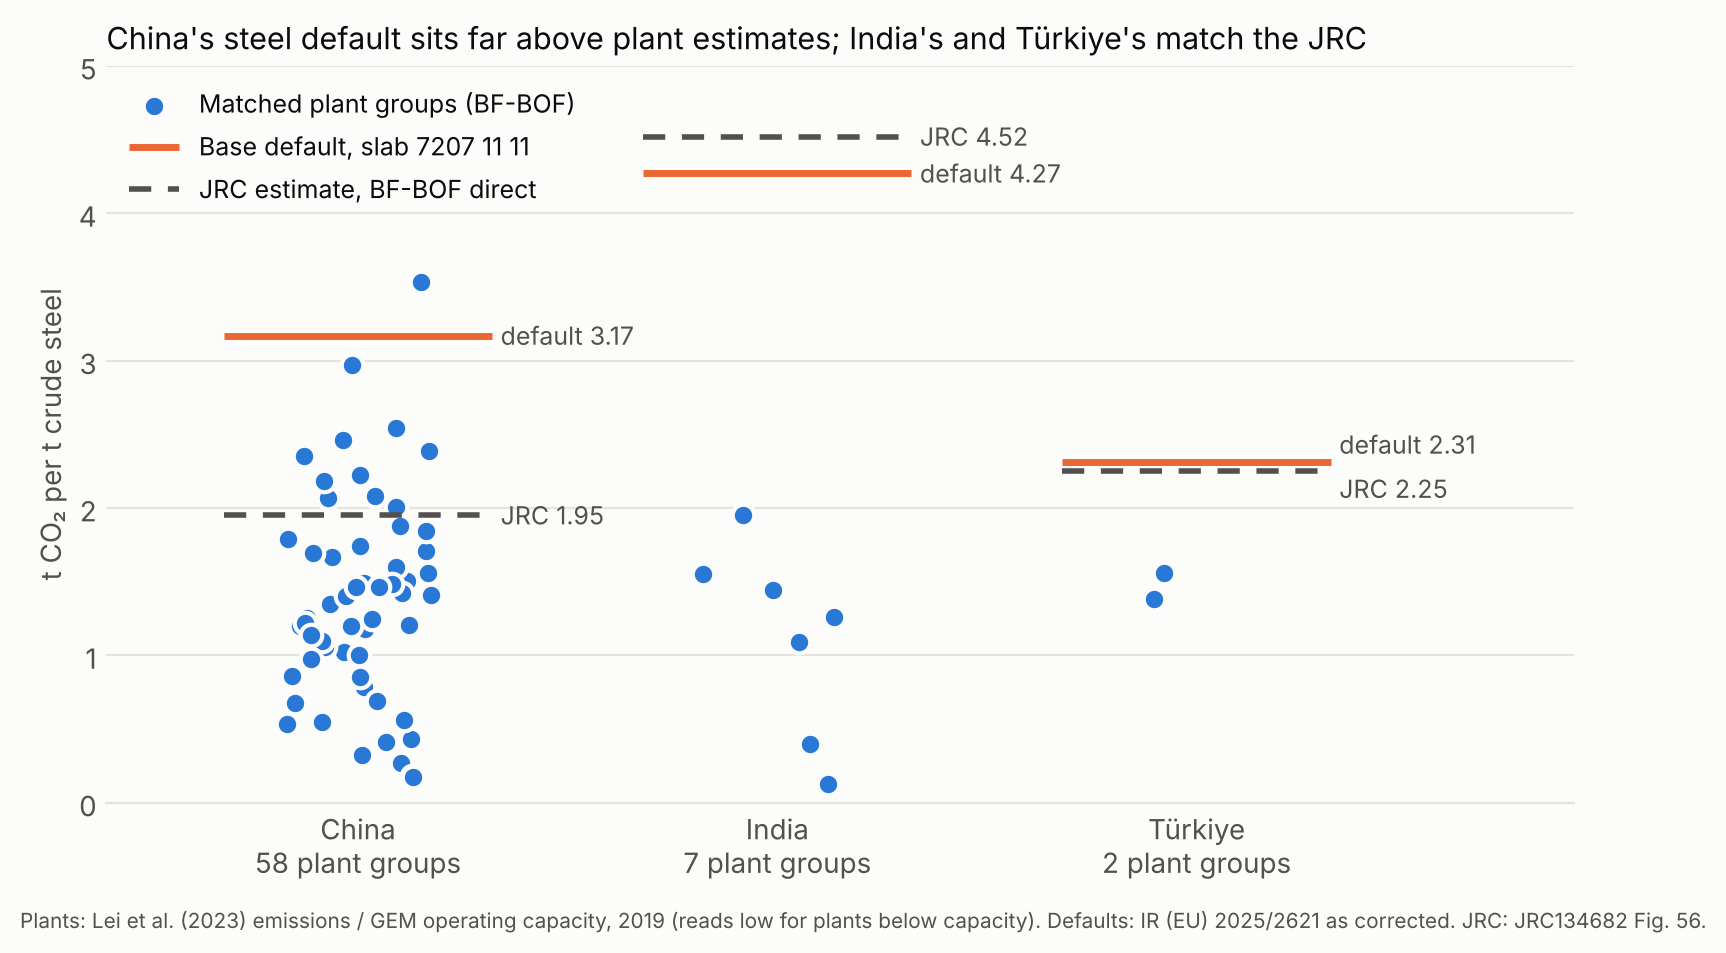

In [10]:
import matplotlib.pyplot as plt
import numpy as np

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
PLANT, DEFAULT = "#2a78d6", "#eb6834"   # blue for plants, orange for defaults

groups = pd.read_csv(PROC / "lei_gem/lei_gem_groups.csv")
bf = groups[(groups.usable == "yes") & (groups.route_class == "BF-BOF")].copy()
bf["intensity"] = pd.to_numeric(bf.intensity_per_t_cap)
jrc = pd.read_csv(PARAMS / "route_reference_intensities.csv")
jrc = jrc[jrc.route.str.startswith("BF-BOF")].set_index("country").direct_tco2e_per_t
slab = dwb[dwb.cn8 == "72071111"].set_index("origin").default_total_tco2e_per_t

countries = [("CHN", "China", "China"), ("IND", "India", "India"), ("TUR", "Türkiye", "Türkiye")]
fig, ax = plt.subplots(figsize=(8, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
rng = np.random.default_rng(1)
for i, (iso, name, jname) in enumerate(countries):
    y = bf.loc[bf.iso3 == iso, "intensity"].to_numpy()
    x = i + rng.uniform(-0.18, 0.18, size=len(y))
    ax.scatter(x, y, s=60, color=PLANT, edgecolor=SURFACE, linewidth=1.5, zorder=3,
               label="Matched plant groups (BF-BOF)" if i == 0 else None)
    d = slab.get(name)
    ax.hlines(d, i - 0.32, i + 0.32, color=DEFAULT, linewidth=2.5, zorder=4,
              label="Base default, slab 7207 11 11" if i == 0 else None)
    j = jrc.get(jname)
    close = j is not None and abs(j - d) < 0.25
    ax.annotate(f"default {d:.2f}", (i + 0.34, d + (0.12 if close and d >= j else -0.12 if close else 0)),
                va="center", fontsize=9, color=INK2)
    if jname in jrc.index:
        ax.hlines(jrc[jname], i - 0.32, i + 0.32, color=INK2, linewidth=2, linestyle=(0, (4, 3)), zorder=4,
                  label="JRC estimate, BF-BOF direct" if i == 0 else None)
        ax.annotate(f"JRC {j:.2f}", (i + 0.34, j + (-0.12 if close and d >= j else 0.12 if close else 0)),
                    va="center", fontsize=9, color=INK2)

counts = [int((bf.iso3 == c[0]).sum()) for c in countries]
ax.set_xticks(range(len(countries)), [f"{c[1]}\n{n} plant groups" for c, n in zip(countries, counts)], color=INK)
ax.set_xlim(-0.6, len(countries) - 0.1)
ax.set_ylim(0, 5)
ax.set_ylabel("t CO₂ per t crude steel", color=INK2)
ax.set_title("China's steel default sits far above plant estimates; India's and Türkiye's match the JRC", loc="left", color=INK, fontsize=11)
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=INK2, length=0)
ax.legend(frameon=False, loc="upper left", fontsize=9, labelcolor=INK)
fig.text(0.01, -0.02, "Plants: Lei et al. (2023) emissions / GEM operating capacity, 2019 (reads low for plants below capacity). "
         "Defaults: IR (EU) 2025/2621 as corrected. JRC: JRC134682 Fig. 56.", fontsize=7.5, color=INK2)
fig.tight_layout()
plt.show()

In [11]:
# same, as a table
rows = []
for iso, name, jname in countries:
    y = bf.loc[bf.iso3 == iso, "intensity"]
    rows.append({"country": name, "plant groups": len(y), "median plant intensity": round(y.median(), 2),
                 "JRC BF-BOF direct": jrc.get(jname), "base default (slab)": slab.get(name),
                 "default / JRC": round(slab.get(name) / jrc.get(jname), 2) if jname in jrc.index else None})
pd.DataFrame(rows)

,country,plant groups,median plant intensity,JRC BF-BOF direct,base default (slab),default / JRC
0,China,58,1.30,1.95,3.169,1.63
1,India,7,1.26,4.52,4.270,0.94
2,Türkiye,2,1.47,2.25,2.310,1.03


## Notes

- Lei et al. (2023) estimate direct emissions from unit capacities, activity rates and default emission factors per process (Supplementary Information, Table S5 and section 1.8). Their spread across plants therefore reflects plant configuration and activity more than efficiency, and their levels need not match CBAM's boundaries.
- Against the JRC estimates, China's slab default is about 1.6 times the BF-BOF figure, while India's and Türkiye's are within about 6%. Pig iron defaults are close to the JRC country estimates for all three.
- Lei's levels for India (about 1.3–1.9) are far below the JRC's 4.5, so Lei's boundary probably differs from CBAM's; that is why only the spread is taken from it.
- The 2027 CBAM benchmarks are not yet published. When they are, replace the benchmarks file in `Data/raw/cbam_tables/` and rerun this notebook.